<a href="https://colab.research.google.com/github/U-mar-404/PE_LLM-Lab06_LSTM_Text_Classification/blob/main/Lab06_LSTM_Text_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Text Classification Using LSTM
**Prompt Engineering and LLM Applications | BSAI 7th Semester | Instructor: Iqra Riaz**

In Lab 03 you built a SimpleRNN classifier. Here everything stays the same except **one layer**: `SimpleRNN` becomes `LSTM`. You will see *why* and *what changes*.

```
Text → IDs → Padding → Embedding → LSTM → Dense + Sigmoid → Probability → Class
```
Run cells top to bottom and answer each **Check yourself** question before moving on.

## Part A — The Problem with SimpleRNN
SimpleRNN memory: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$

The old memory is multiplied by $W_h$ at **every** step. If that factor is below 1 (say 0.4), early words fade fast.

In [ ]:
for steps in [1, 5, 10, 20]:
    print(f"{steps:2d} steps later, word 1 keeps {0.4 ** steps:.10f} of its signal")

 1 steps later, word 1 keeps 0.4000000000 of its signal
 5 steps later, word 1 keeps 0.0102400000 of its signal
10 steps later, word 1 keeps 0.0001048576 of its signal
20 steps later, word 1 keeps 0.0000000110 of its signal


After 10 steps only ~0.01% is left. A review has 200 steps, so the start of the review is almost forgotten. During training the same shrinking happens to gradients: the **vanishing gradient problem**.

**Check yourself:** Why would a long review that starts with "I loved this film..." be hard for SimpleRNN?

## Part B — The LSTM Idea
LSTM = **Long Short-Term Memory**. Two things flow through time:
- **Cell state $C_t$** — long-term memory (a conveyor belt)
- **Hidden state $h_t$** — the output at this step (same role as in SimpleRNN)

Three **gates** (each is a sigmoid → a number between 0 and 1, like a dimmer switch):

| Gate | Question | Symbol |
|---|---|---|
| Forget | How much old memory do I keep? | $f_t$ |
| Input | How much new information do I write? | $i_t$ |
| Output | How much memory do I show as $h_t$? | $o_t$ |

### The six equations (one time step)
1. $f_t = \sigma(W_f [h_{t-1}, x_t] + b_f)$
2. $i_t = \sigma(W_i [h_{t-1}, x_t] + b_i)$
3. $\tilde{c}_t = \tanh(W_c [h_{t-1}, x_t] + b_c)$
4. $C_t = f_t \cdot C_{t-1} + i_t \cdot \tilde{c}_t$  ← **the key line:** keep some old + add some new
5. $o_t = \sigma(W_o [h_{t-1}, x_t] + b_o)$
6. $h_t = o_t \cdot \tanh(C_t)$

SimpleRNN had **1** set of weights. LSTM has **4** (forget, input, candidate, output).

### Small numeric example
Given $C_{t-1}=0.8,\ f=0.9,\ i=0.5,\ \tilde{c}=0.6,\ o=0.7$:
- $C_t = 0.9 \cdot 0.8 + 0.5 \cdot 0.6 = 1.02$
- $h_t = 0.7 \cdot \tanh(1.02) \approx 0.539$

In [ ]:
import numpy as np

def lstm_step(C_prev, f, i, c_cand, o):
    C = f * C_prev + i * c_cand      # key line: keep old + add new
    h = o * np.tanh(C)               # show part of the memory
    return C, h

C, h = lstm_step(C_prev=0.8, f=0.9, i=0.5, c_cand=0.6, o=0.7)
print("C_t =", round(C, 3), "| h_t =", round(h, 3))      # 1.02 and 0.539

print("\nActivity 1: forget gate closed (f = 0.1)")
print(lstm_step(0.8, f=0.1, i=0.5, c_cand=0.6, o=0.7))
print("Activity 2: input gate closed (i = 0)")
print(lstm_step(0.8, f=0.9, i=0.0, c_cand=0.6, o=0.7))

print("\nMemory kept after 10 steps -> SimpleRNN (0.4):", round(0.4**10, 5), "| LSTM gate (0.9):", round(0.9**10, 3))

C_t = 1.02 | h_t = 0.539

Activity 1: forget gate closed (f = 0.1)
(0.38, np.float64(0.25389522730463576))
Activity 2: input gate closed (i = 0)
(0.7200000000000001, np.float64(0.4318365120139455))

Memory kept after 10 steps -> SimpleRNN (0.4): 0.0001 | LSTM gate (0.9): 0.349


**Check yourself:** In Activity 1, what happened to `C_t` and why? In Activity 2, where did `C_t` come from?

## Step 1 — Setup and Data (same as Lab 03)

In [ ]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42); tf.random.set_seed(42)
VOCAB, MAXLEN = 10000, 200

(X_train_raw, y_train), (X_test_raw, y_test) = imdb.load_data(num_words=VOCAB)
X_train = pad_sequences(X_train_raw, maxlen=MAXLEN)
X_test  = pad_sequences(X_test_raw,  maxlen=MAXLEN)
print("Shapes:", X_train.shape, X_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shapes: (25000, 200) (25000, 200)


**Check yourself:** What does each row of `X_train` represent? Why 200 columns?

## Step 2 — Build the LSTM Model
One function builds either model. **Only the RNN layer changes.**

In [ ]:
def build_model(cell="lstm", max_len=MAXLEN, emb_dim=128, units=128):
    rnn = LSTM(units) if cell == "lstm" else SimpleRNN(units)
    return Sequential([
        Input(shape=(max_len,)),
        Embedding(VOCAB, emb_dim),
        rnn,
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

model = build_model("lstm")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

print("Embedding:", VOCAB * 128)
print("LSTM     :", 4 * (128*128 + 128*128 + 128), "= 4 gates x (Wx + Wh + b)")
print("Dense    :", 128 + 1)
print("SimpleRNN layer would have:", 128*128 + 128*128 + 128)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,411,713 (5.39 MB)

 Trainable params: 1,411,713 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

Embedding: 1280000
LSTM     : 131584 = 4 gates x (Wx + Wh + b)
Dense    : 129
SimpleRNN layer would have: 32896


**Check yourself:** Why does the LSTM layer have exactly 4 times the parameters of the SimpleRNN layer?

## Step 3 — Train
Same loop as Lab 03: forward pass → loss → backpropagation through time → Adam. LSTM is usually slower per epoch.

In [ ]:
t0 = time.time()
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.2)
print(f"Training time: {time.time() - t0:.0f} s")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 171s 539ms/step - accuracy: 0.7897 - loss: 0.4395 - val_accuracy: 0.8702 - val_loss: 0.3162
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 169s 540ms/step - accuracy: 0.8963 - loss: 0.2640 - val_accuracy: 0.8740 - val_loss: 0.3178
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 166s 532ms/step - accuracy: 0.9117 - loss: 0.2321 - val_accuracy: 0.8554 - val_loss: 0.3768
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 177s 567ms/step - accuracy: 0.9330 - loss: 0.1800 - val_accuracy: 0.8660 - val_loss: 0.4219
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 175s 560ms/step - accuracy: 0.9244 - loss: 0.2025 - val_accuracy: 0.8646 - val_loss: 0.4454
Training time: 859 s


## Step 4 — Training Curves

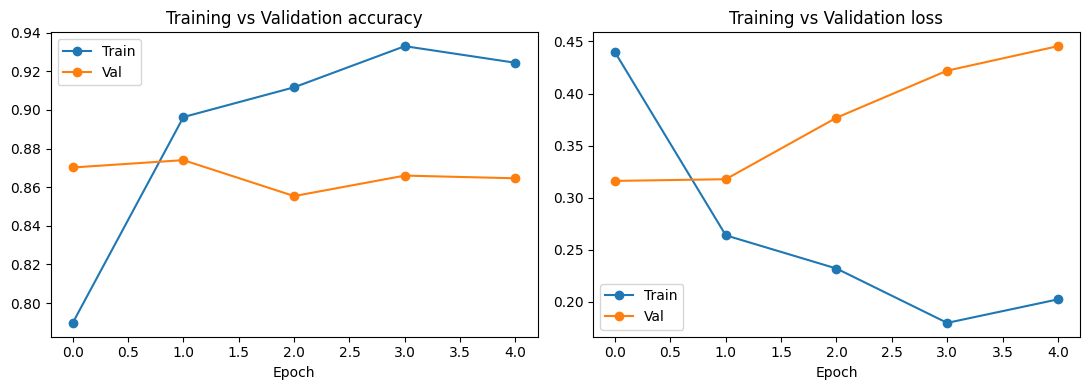

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m in zip(ax, ["accuracy", "loss"]):
    a.plot(history.history[m], marker="o"); a.plot(history.history["val_" + m], marker="o")
    a.set_title(f"Training vs Validation {m}"); a.set_xlabel("Epoch"); a.legend(["Train", "Val"])
plt.tight_layout(); plt.show()

**Check yourself:** Is the model learning? Is there overfitting?

## Step 5 — Evaluate

LSTM test accuracy: 0.8538
              precision    recall  f1-score   support

    Negative       0.87      0.83      0.85     12500
    Positive       0.84      0.88      0.86     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



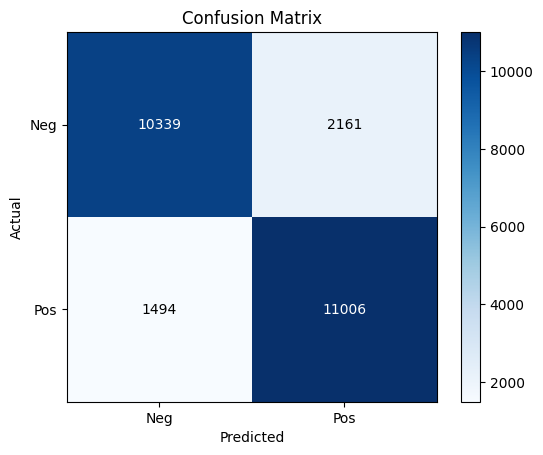

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("LSTM test accuracy:", round(test_acc, 4))

y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).ravel()
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks([0, 1], ["Neg", "Pos"]); plt.yticks([0, 1], ["Neg", "Pos"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
plt.show()

## Step 6 — Predict a New Sentence
Same preprocessing as training. Words outside the 10,000-word vocabulary map to ID 2.

In [ ]:
word_index = imdb.get_word_index()

def encode(text):
    words = text.lower().replace(".", "").replace(",", "").replace("!", "").replace("?", "").split()
    ids = [1]
    for w in words:
        i = word_index.get(w)
        ids.append(i + 3 if i is not None and i + 3 < VOCAB else 2)
    return ids

def predict(text, m=None):
    m = m or model
    p = float(m.predict(pad_sequences([encode(text)], maxlen=MAXLEN), verbose=0)[0][0])
    print(f"{p:.3f} -> {'Positive' if p >= 0.5 else 'Negative':8s} | {text}")

for s in ["This movie was fantastic and I really enjoyed it",
          "What a terrible film, a complete waste of time",
          "Not bad, but I expected much more from the director",
          "I loved the first hour and the acting was wonderful but the ending was a boring mess that ruined everything"]:
    predict(s)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
0.841 -> Positive | This movie was fantastic and I really enjoyed it
0.004 -> Negative | What a terrible film, a complete waste of time
0.072 -> Negative | Not bad, but I expected much more from the director
0.257 -> Negative | I loved the first hour and the acting was wonderful but the ending was a boring mess that ruined everything


**Your turn:** add at least 2 sentences of your own, including one where an early opinion is followed by many neutral words.

## Step 7 — Verify the LSTM Equations Against Keras
Keras stores the four gates side by side in one matrix of width 4 × 128 = 512, in the order **input, forget, candidate, output**. We recompute the final hidden state ourselves.

In [ ]:
sample = pad_sequences([encode("This movie was fantastic and I really enjoyed it")], maxlen=MAXLEN)
h_keras = tf.keras.Model(model.inputs, model.layers[1].output).predict(sample, verbose=0)[0]

E = model.layers[0].get_weights()[0]
W, U, b = model.layers[1].get_weights()       # (128,512), (128,512), (512,)
sig = lambda z: 1 / (1 + np.exp(-z))

h, C = np.zeros(128), np.zeros(128)
for tok in sample[0]:
    z = E[tok] @ W + h @ U + b
    i, f, c_cand, o = np.split(z, 4)
    i, f, o = sig(i), sig(f), sig(o)
    C = f * C + i * np.tanh(c_cand)
    h = o * np.tanh(C)

print("W shape:", W.shape, "| max |manual - Keras|:", np.abs(h - h_keras).max())

W shape: (128, 512) | max |manual - Keras|: 7.269941162957316e-08


**Check yourself:** Why is the difference ≈ 0? What does that tell you about the Keras `LSTM` layer?

## Step 8 — SimpleRNN vs LSTM Experiments
Both models, same data. (3 epochs to save time.) The **length 400** rows are the real test: the farther the important words are from the end, the harder it is for SimpleRNN.

In [ ]:
def run(name, cell, max_len=200, epochs=3):
    Xtr = pad_sequences(X_train_raw, maxlen=max_len)
    Xte = pad_sequences(X_test_raw,  maxlen=max_len)
    m = build_model(cell, max_len)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    m.fit(Xtr, y_train, epochs=epochs, batch_size=64, validation_split=0.2, verbose=0)
    t = time.time() - t0
    acc = m.evaluate(Xte, y_test, verbose=0)[1]
    print(f"{name:22s} acc={acc:.4f} time={t:.0f}s")
    return {"Experiment": name, "Cell": cell, "Length": max_len,
            "Params": m.count_params(), "Test Acc": round(acc, 4), "Time (s)": round(t)}

results = [
    run("SimpleRNN, len 200", "simple", 200),
    run("LSTM, len 200",      "lstm",   200),
    run("SimpleRNN, len 400", "simple", 400),
    run("LSTM, len 400",      "lstm",   400),
]
df = pd.DataFrame(results); df["Observation"] = ""      # write your own observation per row
df

SimpleRNN, len 200     acc=0.6607 time=247s


**Observations (write your own):**
- Length 200: …
- Length 400: …
- Cost of LSTM (parameters, time): …

### SimpleRNN vs LSTM
| | SimpleRNN | LSTM |
|---|---|---|
| Memory | One hidden state $h_t$ | Cell state $C_t$ + hidden state $h_t$ |
| Gates | None | Forget, input, output |
| Memory update | Overwritten by tanh every step | Keeps what it needs, adds what is new |
| RNN-layer params (128/128) | 32,896 | 131,584 (4×) |
| Long sequences | Early words fade | Carries information much longer |
| Speed | Faster | Slower per epoch |

---
### Lab Questions
1. Why does a SimpleRNN forget the beginning of a long review?
 A SimpleRNN may lose old information as it reads more words.
This makes it difficult to remember important words from the beginning.
2. What is the difference between the cell state $C_t$ and the hidden state $h_t$?
The cell state Ct stores long-term information.
The hidden state ht carries information used for the current output.
3. What does the forget gate do? What if $f_t = 0$? If $f_t = 1$?
The forget gate decides how much old information to keep.
If ft=0, it forgets the old information; if ft=1, it keeps it all.
4. Why do gates use sigmoid but the candidate memory uses tanh?
Sigmoid gives values between 0 and 1 to control information.
Tanh gives values between -1 and 1 to create new information.
5. Why does the LSTM layer have exactly 4× the parameters of SimpleRNN?
An LSTM has four parts: forget gate, input gate, candidate memory, and output gate.
Each part has its own weights, so it has about four times as many parameters.
6. Why is $C_t = f_t C_{t-1} + i_t \tilde{c}_t$ better at keeping information than repeated tanh squashing?
This formula allows old information to pass forward without repeated tanh squashing.
So, an LSTM can remember important information for a longer time.
7. Compare SimpleRNN and LSTM at length 200 and 400. Where did LSTM help, and what did it cost?
LSTM usually remembers important information better in long reviews of 200 or 400 words.
However, it has more parameters and needs more time and computing power to train.
8. Give one sentence where early words matter for the sentiment. Did both models get it right?
Example: “I thought the movie would be boring, but it was amazing.” The early words give a different meaning from the ending.
LSTM may understand the full meaning better, but whether both models got it right depends on your notebook's results.

### One-sentence takeaway
*An LSTM is a SimpleRNN with a protected memory lane: three gates decide what to forget, what to write and what to show, so useful information can travel across many time steps.*